# Défi NLP medRxiv 2026, projet 2 : détection des abstracts générés par une IA
## Script 1 : méthodes classiques (TF-IDF, stylométrie, machine learning)

**Contexte :** de plus en plus de textes scientifiques sont écrits par des modèles de langage (LLM). Le jeu de données mélange des abstracts de preprints déposés sur medRxiv entre mars et septembre 2026 et des abstracts générés par plusieurs LLM à partir du titre et de l'abstract d'un vrai preprint. À la lecture, on les distingue mal, mais il existe des indices comme le vocabulaire, la longueur ou la régularité des phrases.

**Objectif :** prédire si un abstract a été écrit par un humain (**0**) ou généré par une IA (**1**).

importer "ClassificationsHumanAI_AbstractsTrainSet.csv.gz" et "ClassificationsHumanAI_AbstractsTestSet.csv.gz"

Plan :
 1. découverte des données
 2. nettoyage
 3. variables stylométriques
 4. modèles, validation croisée et seuil
 5. visualisation des résultats
 6. bruit d'étiquetage
 7. robustesse du modèle sans les indices de mise en forme
 8. modèle final et prédiction du fichier de test
 9. conclusion

In [1]:
import pandas as pd
import numpy as np
import os


fichier_donnees = "ClassificationsHumanAI_AbstractsTrainSet.csv.gz"   #données d'apprentissage
fichier_test = "ClassificationsHumanAI_AbstractsTestSet.csv.gz"       #fichier à prédire
fichier_sortie = "predictions_script1.csv"                            #fichier de prédictions (ID, pred)
dossier_figures = "figures_script1"                                   #figures et tableaux
os.makedirs(dossier_figures, exist_ok=True)

GRAINE = 42                  #graine aléatoire, pour avoir des résultats reproductibles
COL_LABEL = "HumanAI"        #variable à prédire (0 = humain, 1 = IA)
ANALYSE_ROBUSTESSE = True    #mettre False pour sauter l'étape 7

## 1. découverte des données
On commence par regarder à quoi ressemblent les données :
* la taille des tableaux et la répartition des classes (combien d'abstracts IA)
* les abstracts vides et les doublons
* la longueur des textes selon la classe
* si la discipline (`category`) est liée à la classe
* quelques indices de mise en forme (titres de section, apostrophes, tirets longs...)

In [2]:
def charger(chemin):
    df = pd.read_csv(chemin, sep=";")
    df["abstract"] = df["abstract"].fillna("").astype(str)   #les abstracts manquants deviennent ""
    return df

train = charger(fichier_donnees)
test = charger(fichier_test)
print("Entraînement :", train.shape, "| Test :", test.shape)

#les 5 premières lignes du tableau
train.head()

Entraînement : (10000, 4) | Test : (2898, 3)


,ID,category,abstract,HumanAI
0,1,Health Informatics,BackgroundDigital decision-support tools such ...,0
1,2,Public And Global Health,Background: High body mass index (BMI) represe...,1
2,3,Epidemiology,BackgroundRabies is a zoonotic neglected publi...,0
3,4,Oncology,"In the randomized SU2C-SARC032 trial, the addi...",1
4,5,Neurology,Gene therapy is rapidly emerging as a transfor...,0


In [3]:
#déséquilibre des classes
print("Répartition des classes (0 = humain, 1 = IA) :")
print(train[COL_LABEL].value_counts().to_string())
part_ia = train[COL_LABEL].mean()
print(f"-> {part_ia:.1%} d'abstracts IA : classes déséquilibrées.")
#tout prédire "IA" donne un rappel de 1 et une précision égale à part_ia, donc F1 = 2p / (1 + p)
print(f"-> F1 d'un modèle qui répond toujours 'IA' : {2 * part_ia / (1 + part_ia):.3f}")

#abstracts vides
vides = train["abstract"].str.strip() == ""
print(f"\nAbstracts vides : {vides.sum()} dans le train, "
      f"{(test['abstract'].str.strip() == '').sum()} dans le test")
print("Classe des abstracts vides du train :",
      train.loc[vides, COL_LABEL].value_counts().to_dict())

#doublons exacts (hors vides)
non_vides = train[~vides]
n_doublons = non_vides["abstract"].duplicated().sum()
conflits = (non_vides.groupby("abstract")[COL_LABEL].nunique() > 1).sum()
print(f"\nDoublons exacts (hors vides) : {n_doublons} lignes, "
      f"dont {conflits} avec des étiquettes contradictoires")

#longueur des textes
train["n_mots"] = train["abstract"].str.split().str.len()
print("\nNombre de mots par classe (hors vides) :")
print(train[~vides].groupby(COL_LABEL)["n_mots"].describe()[["mean", "50%", "min", "max"]].round(0))

#la discipline (category) est-elle informative ?
prop_par_cat = train[~vides].groupby("category")[COL_LABEL].mean()
print(f"\nPart d'IA par discipline : de {prop_par_cat.min():.0%} à {prop_par_cat.max():.0%} "
      f"(médiane {prop_par_cat.median():.0%})")

Répartition des classes (0 = humain, 1 = IA) :
HumanAI
0    7127
1    2873
-> 28.7% d'abstracts IA : classes déséquilibrées.
-> F1 d'un modèle qui répond toujours 'IA' : 0.446

Abstracts vides : 752 dans le train, 223 dans le test
Classe des abstracts vides du train : {1: 752}

Doublons exacts (hors vides) : 860 lignes, dont 0 avec des étiquettes contradictoires



Nombre de mots par classe (hors vides) :
          mean    50%   min     max
HumanAI                            
0        287.0  263.0  19.0  1281.0
1        257.0  252.0   1.0   719.0

Part d'IA par discipline : de 11% à 38% (médiane 22%)


In [4]:
#indices de mise en forme, proportion d'abstracts qui contiennent chaque motif
ENTETES = (r"(?:Background|Introduction|Objectives?|Aims?|Purpose|Rationale|Importance|"
           r"Methods|Design|Setting|Participants|Results|Findings|Conclusions?|Interpretation)")
indices = {
    "titre collé (MethodsWe...)": r"\b" + ENTETES + r"[A-Z][a-z]",
    "titre suivi de ':'":         r"\b" + ENTETES + r"\s*:",
    "caractère non-ASCII":        r"[^\x00-\x7f]",
    "apostrophe":                 r"['’]",
    "tiret long (— ou –)":        r"[—–]",
    "double espace":              r"  ",
    "retour à la ligne":          r"\n",
}
tableau = pd.DataFrame({
    "humain (train)": [non_vides.loc[non_vides[COL_LABEL] == 0, "abstract"].str.contains(p).mean() for p in indices.values()],
    "IA (train)":     [non_vides.loc[non_vides[COL_LABEL] == 1, "abstract"].str.contains(p).mean() for p in indices.values()],
    "test":           [test["abstract"].str.contains(p).mean() for p in indices.values()],
}, index=list(indices.keys()))
tableau.round(3).to_csv(os.path.join(dossier_figures, "indices_mise_en_forme.csv"))
tableau.round(3)

,humain (train),IA (train),test
titre collé (MethodsWe...),0.593,0.000,0.418
titre suivi de ':',0.005,0.307,0.078
caractère non-ASCII,0.000,0.227,0.052
apostrophe,0.003,0.164,0.039
tiret long (— ou –),0.000,0.174,0.040
double espace,0.045,0.288,0.092
retour à la ligne,0.723,0.320,0.563


* Les abstracts vides sont tous étiquetés IA dans le train. Ce sont sûrement des générations qui ont échoué (le LLM n'a rien renvoyé), donc c'est un défaut de construction du jeu de données et pas un style d'écriture. On les traite à part avec une règle simple, un abstract vide est classé 1.
* Les doublons sont surtout des abstracts humains (versions successives d'un même preprint). Si on les garde, un même texte peut tomber à la fois dans un pli d'apprentissage et dans le pli de validation, et la validation croisée devient trop optimiste. On les retire donc.
* La part d'IA est à peu près la même dans chaque discipline (les écarts viennent des petites disciplines), donc on n'utilise pas `category`.
* Pour la mise en forme, les abstracts humains récupérés sur medRxiv ont souvent leurs titres de section collés au texte ("MethodsWe recruited..."), pas d'apostrophe ("Parkinsons disease") et aucun caractère non-ASCII. Les textes IA ont plus souvent des tirets longs, des titres suivis de deux-points ou des doubles espaces. Ces indices séparent très bien les deux classes, mais ils viennent en partie de la façon dont les textes ont été collectés (artefacts). À l'étape 7, on regarde ce que vaut le modèle quand on les efface.

## 2. nettoyage
* On fait un nettoyage volontairement léger, en retirant seulement les balises HTML qui restent et les espaces au début et à la fin.
* On ne met pas en minuscules et on garde la ponctuation, les espaces multiples et les retours à la ligne. Pour reconnaître une IA, c'est justement la façon d'écrire qui nous intéresse (ponctuation, typographie, mise en forme).
* Le jeu d'apprentissage ne contient ni les abstracts vides (traités par la règle) ni les doublons exacts.
* Le nettoyage est écrit sous forme de fonction pour pouvoir l'appliquer aussi au fichier test (étape 8).

In [5]:
import re    #expressions régulières, pour rechercher ou remplacer des motifs dans un texte

def nettoyer(texte):
    texte = re.sub(r"<[^>]+>", " ", texte)     #balises HTML, ex. <sup>, </i>
    return texte.strip()

train["texte"] = train["abstract"].map(nettoyer)
test["texte"] = test["abstract"].map(nettoyer)

#jeu utilisé pour l'apprentissage, sans les vides et sans les doublons exacts
donnees = (train[train["texte"] != ""]
           .drop_duplicates(subset="texte")
           .reset_index(drop=True))
X = donnees["texte"].values
y = donnees[COL_LABEL].values
print(f"Après nettoyage : {len(donnees)} abstracts "
      f"({y.sum()} IA, {(y == 0).sum()} humains)")

Après nettoyage : 8388 abstracts (2103 IA, 6285 humains)


## 3. variables stylométriques
On calcule une trentaine d'indicateurs de style pour chaque abstract. Les comptages sont rapportés à 100 mots pour ne pas dépendre de la longueur du texte. On regarde :
* la longueur (nombre de mots et de phrases)
* la régularité des phrases (longueur moyenne, écart-type, coefficient de variation), pour voir si une IA écrit des phrases plus homogènes
* la richesse du vocabulaire (longueur des mots, TTR qui est la part de mots différents, hapax qui sont les mots vus une seule fois)
* des mots souvent associés aux LLM (delve, pivotal, crucial, furthermore...). On regarde s'ils servent encore aujourd'hui, sachant que des humains les utilisent aussi, parfois parce qu'ils se sont aidés d'un outil d'IA (c'est la question du bruit d'étiquetage)
* la lisibilité avec le score de Flesch (plus il est haut, plus le texte est facile à lire)
* la ponctuation, les résultats chiffrés et la typographie (tirets longs, apostrophes, titres de section)

In [6]:
from collections import Counter    #compte les occurrences de chaque mot

MOTS_LLM = ("delve", "underscore", "pivotal", "crucial", "notably", "furthermore",
            "moreover", "additionally", "comprehensive", "robust", "insight",
            "highlight", "landscape", "intricate", "nuanced", "multifaceted", "leverag")

def compter_syllabes(mot):
    #approximation par le nombre de groupes de voyelles (suffisant pour un score de lisibilité)
    n = len(re.findall(r"[aeiouy]+", mot.lower()))
    if mot.lower().endswith("e") and n > 1:      #'e' final muet (ex. "made")
        n -= 1
    return max(n, 1)

def variables_stylometriques(texte):
    #calcule les indicateurs de style pour UN abstract
    mots = re.findall(r"[A-Za-z]+", texte)
    n_mots = max(len(mots), 1)                   #max(...,1) évite une division par 0 si le texte est vide
    n_car = max(len(texte), 1)
    #découpage en phrases après . ! ou ? suivi d'un espace
    phrases = [p for p in re.split(r"(?<=[.!?])\s+", texte) if p.strip()]
    longueurs = np.array([len(p.split()) for p in phrases]) if phrases else np.array([0])
    mots_min = [m.lower() for m in mots]
    frequences = Counter(mots_min)
    nombres = re.findall(r"\d+(?:\.\d+)?", texte)
    syllabes = sum(compter_syllabes(m) for m in mots)

    v = {}
    #longueur
    v["n_mots"] = len(mots)
    v["n_phrases"] = len(phrases)
    #régularité des phrases
    v["phrase_long_moy"] = longueurs.mean()
    v["phrase_long_ecart_type"] = longueurs.std()
    v["phrase_long_cv"] = longueurs.std() / (longueurs.mean() + 1e-6)   #coefficient de variation
    v["phrase_long_max"] = longueurs.max()
    #richesse lexicale
    v["mot_long_moy"] = np.mean([len(m) for m in mots]) if mots else 0
    v["ttr"] = len(frequences) / n_mots                   #type/token ratio (mots différents/nombre de mots)
    v["hapax"] = sum(c == 1 for c in frequences.values()) / n_mots   #mots vus une seule fois
    v["mots_llm"] = 100 * sum(m.startswith(MOTS_LLM) for m in mots_min) / n_mots
    v["nous"] = 100 * (frequences["we"] + frequences["our"]) / n_mots
    #lisibilité (score de Flesch)
    v["flesch"] = 206.835 - 1.015 * (len(mots) / max(len(phrases), 1)) - 84.6 * (syllabes / n_mots)
    #ponctuation (pour 100 mots)
    for nom, signe in [("virgules", ","), ("points_virgules", ";"), ("deux_points", ":"),
                       ("parentheses", "("), ("traits_union", "-"), ("pourcents", "%")]:
        v[nom] = 100 * texte.count(signe) / n_mots
    #résultats chiffrés (précision des nombres)
    v["prop_chiffres"] = sum(c.isdigit() for c in texte) / n_car
    v["nombres"] = 100 * len(nombres) / n_mots
    v["prop_decimaux"] = sum("." in x for x in nombres) / max(len(nombres), 1)
    v["prop_majuscules"] = sum(c.isupper() for c in texte) / n_car
    #typographie/mise en forme (cf. tableau de l'étape 1)
    v["non_ascii"] = sum(ord(c) > 127 for c in texte)
    v["tirets_longs"] = texte.count("—") + texte.count("–")
    v["apostrophes"] = texte.count("'") + texte.count("’")
    v["doubles_espaces"] = texte.count("  ")
    v["retours_ligne"] = texte.count("\n")
    v["titres_colles"] = len(re.findall(r"\b" + ENTETES + r"[A-Z][a-z]", texte))
    v["titres_deux_points"] = len(re.findall(r"\b" + ENTETES + r"\s*:", texte))
    v["titres_espace"] = len(re.findall(r"(?:^|\s)" + ENTETES + r"\s+[A-Z]", texte))
    v["lettres_grecques_accolades"] = len(re.findall(r"\{[a-z]+\}", texte))   #nombre de {rho}, {beta}...
    v["finit_par_point"] = int(bool(re.search(r"[.!?)\]]\s*$", texte)))       #texte tronqué ?
    return v

def tableau_stylometrique(textes):
    #applique variables_stylometriques à une liste de textes et renvoie un tableau
    return pd.DataFrame([variables_stylometriques(t) for t in textes])

S = tableau_stylometrique(X)
print(S.shape[1], "variables stylométriques calculées")
print("Moyenne par classe (quelques variables) :")
print(S.groupby(y).mean()[["n_mots", "phrase_long_moy", "phrase_long_cv", "ttr",
                           "mots_llm", "flesch", "prop_decimaux"]].T.round(3)
      .rename(columns={0: "humain", 1: "IA"}).to_string())

32 variables stylométriques calculées
Moyenne par classe (quelques variables) :
                  humain       IA
n_mots           287.088  257.678
phrase_long_moy   22.369   22.629
phrase_long_cv     0.396    0.360
ttr                0.584    0.604
mots_llm           0.240    0.305
flesch             7.563    6.520
prop_decimaux      0.260    0.251


## 4. modèles, validation croisée et seuil
* On utilise une **validation croisée stratifiée à 5 plis** sur le jeu d'entraînement seul, chaque pli garde environ 25 % d'IA. `cross_val_predict` renvoie des probabilités hors pli, c'est-à-dire que chaque abstract est prédit par un modèle qui ne l'a pas vu pendant l'apprentissage.
* On compare 4 modèles de base :
  * Naive Bayes sur un sac de mots, la référence classique. On s'attend à ce qu'il soit faible ici car il suppose les mots indépendants et s'appuie surtout sur le sujet du texte, alors qu'humains et IA parlent des mêmes sujets.
  * TF-IDF sur les mots (1-2 grammes) avec une régression logistique. `sublinear_tf` remplace tf par log(1 + tf) pour atténuer les mots très répétés, et C = 10 donne une régularisation faible (choisi par essais).
  * TF-IDF sur les n-grammes de caractères (1 à 4) avec une régression logistique. Avec `lowercase=False`, on garde les majuscules, les espaces et la ponctuation, ce qui permet de capter la typographie et des morceaux de mots. Il est donc plus robuste aux variations de vocabulaire (après quelques essais, char 1-4 a donné de meilleurs résultats que char 2-5 et char_wb 2-5).
  * Les variables stylométriques avec un gradient boosting (`HistGradientBoostingClassifier`, rapide et sans besoin de standardiser).
* Pour le déséquilibre des classes, on met `class_weight="balanced"`, les erreurs sur la classe rare (IA) comptent plus.
* Le stacking (super-learner) est un gradient boosting qui reçoit les 2 probabilités TF-IDF et les variables stylométriques, et qui apprend à les combiner. On lui donne les probabilités hors pli, sinon il verrait des probabilités trop confiantes (calculées sur les données d'entraînement des modèles) et leur ferait trop confiance.
* Par défaut on prédit IA quand la probabilité dépasse 0,5, mais avec des classes déséquilibrées ce n'est pas forcément le meilleur choix pour le F1. On cherche donc le seuil qui maximise le F1.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline                      #enchaîne vectorisation + classifieur
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

#validation croisée à 5 plis (stratifiée = même part d'IA dans chaque pli)
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)

def modele_naive_bayes():
    #sac de mots (comptages) + Naive Bayes multinomial
    return make_pipeline(CountVectorizer(ngram_range=(1, 2), min_df=2),
                         MultinomialNB(alpha=0.5))

def modele_mots():
    #TF-IDF sur les mots (1-2 grammes) + régression logistique
    return make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=200_000, sublinear_tf=True),
        LogisticRegression(C=10, class_weight="balanced", max_iter=3000))

def modele_caracteres():
    #TF-IDF sur les n-grammes de caractères (1 à 4) + régression logistique
    return make_pipeline(
        TfidfVectorizer(analyzer="char", ngram_range=(1, 4), min_df=3,
                        max_features=300_000, sublinear_tf=True, lowercase=False),
        LogisticRegression(C=10, class_weight="balanced", max_iter=3000))

def modele_boosting():
    #gradient boosting pour les variables tabulaires (stylométrie)
    return HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,
                                          class_weight="balanced", random_state=GRAINE)

def proba_hors_pli(modele, X_, y_, cv):
    #probabilité d'être IA, hors pli, pour chaque abstract
    return cross_val_predict(modele, X_, y_, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

def meilleur_seuil(y_, proba):
    #seuil qui maximise le F1 (on teste 0.05, 0.06, ..., 0.95)
    seuils = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [f1_score(y_, (proba >= s).astype(int)) for s in seuils]
    i = int(np.argmax(f1s))
    return seuils[i], f1s[i]

def scores(nom, y_, proba, seuil=0.5):
    #résumé des métriques pour un modèle et un seuil donnés
    pred = (proba >= seuil).astype(int)
    return {"modèle": nom, "seuil": seuil,
            "F1": f1_score(y_, pred), "précision": precision_score(y_, pred),
            "rappel": recall_score(y_, pred), "AUC": roc_auc_score(y_, proba)}

def construire_niveau2(S_, p_mots, p_car):
    #variables du modèle de niveau 2 = stylométrie + 2 probabilités TF-IDF
    Z = S_.copy()
    Z["proba_tfidf_mots"] = p_mots
    Z["proba_tfidf_caracteres"] = p_car
    return Z

def pipeline_complet(textes, y_, S_):
    #toute la chaîne en validation croisée, renvoie les probabilités hors pli de chaque modèle
    #(fonction réutilisée à l'étape 7)
    p = {}
    p["Naive Bayes (mots)"] = proba_hors_pli(modele_naive_bayes(), textes, y_, plis)
    p["TF-IDF mots + LR"] = proba_hors_pli(modele_mots(), textes, y_, plis)
    p["TF-IDF caractères + LR"] = proba_hors_pli(modele_caracteres(), textes, y_, plis)
    p["Stylométrie + boosting"] = proba_hors_pli(modele_boosting(), S_, y_, plis)
    #stacking, le niveau 2 est entraîné sur les probabilités hors pli des modèles TF-IDF
    Z = construire_niveau2(S_, p["TF-IDF mots + LR"], p["TF-IDF caractères + LR"])
    plis2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE + 1)  #autre découpage
    p["Stacking (final)"] = proba_hors_pli(modele_boosting(), Z, y_, plis2)
    return p

In [8]:
print("Validation croisée (5 plis)")
probas = pipeline_complet(X, y, S)

#tableau des résultats avec chaque modèle au seuil 0,5 puis au seuil optimisé pour le F1
resultats = []
for nom, p in probas.items():
    resultats.append(scores(nom, y, p, 0.5))            #seuil par défaut
    s, _ = meilleur_seuil(y, p)
    resultats.append(scores(nom, y, p, s))              #seuil optimisé pour le F1
resultats = pd.DataFrame(resultats)
resultats.round(4).to_csv(os.path.join(dossier_figures, "resultats_validation_croisee.csv"), index=False)
print("\nRésultats en validation croisée (hors abstracts vides) :")
print(resultats.round(3).to_string(index=False))

#seuil retenu pour le modèle final
p_final = probas["Stacking (final)"]
SEUIL, f1_cv = meilleur_seuil(y, p_final)
print(f"\nSeuil retenu : {SEUIL} -> F1 hors pli = {f1_cv:.3f}")

#F1 sur tout le jeu d'entraînement, abstracts vides inclus (règle vide = IA),
#c'est-à-dire dans les conditions du jeu de test
n_vides_ia = int(train.loc[train["texte"] == "", COL_LABEL].sum())
pred_cv = (p_final >= SEUIL).astype(int)
vp = int(((pred_cv == 1) & (y == 1)).sum()) + n_vides_ia      #vrais positifs
fp = int(((pred_cv == 1) & (y == 0)).sum())                   #faux positifs
fn = int(((pred_cv == 0) & (y == 1)).sum())                   #faux négatifs
print(f"F1 estimé en incluant les {n_vides_ia} abstracts vides (règle vide -> IA) : "
      f"{2 * vp / (2 * vp + fp + fn):.3f}")

#probabilités hors pli du modèle final, le script 2 s'en sert pour comparer les deux scripts sur les mêmes abstracts
pd.DataFrame({"ID": donnees["ID"], "proba_IA": p_final}).to_csv(
    os.path.join(os.path.dirname(os.path.abspath(fichier_sortie)), "probas_hors_pli_script1.csv"),
    index=False)

Validation croisée (5 plis)



Résultats en validation croisée (hors abstracts vides) :
                modèle  seuil    F1  précision  rappel   AUC
    Naive Bayes (mots)   0.50 0.373      0.707   0.253 0.810
    Naive Bayes (mots)   0.05 0.417      0.699   0.297 0.810
      TF-IDF mots + LR   0.50 0.743      0.845   0.663 0.937
      TF-IDF mots + LR   0.40 0.769      0.757   0.782 0.937
TF-IDF caractères + LR   0.50 0.810      0.831   0.789 0.956
TF-IDF caractères + LR   0.47 0.813      0.814   0.812 0.956
Stylométrie + boosting   0.50 0.809      0.865   0.760 0.960
Stylométrie + boosting   0.72 0.822      0.952   0.723 0.960
      Stacking (final)   0.50 0.863      0.872   0.854 0.979
      Stacking (final)   0.55 0.865      0.885   0.845 0.979

Seuil retenu : 0.55 -> F1 hors pli = 0.865
F1 estimé en incluant les 752 abstracts vides (règle vide -> IA) : 0.901


Le seuil est choisi sur les mêmes prédictions hors pli que celles qui servent à calculer le F1, donc ce F1 est très légèrement optimiste. Comme la courbe du F1 en fonction du seuil est plate autour du maximum, l'effet est minime. La validation croisée imbriquée plus bas le confirme.

* Naive Bayes est faible (F1 = 0,417) car il s'appuie sur le sujet du texte et pas sur le style, alors qu'humains et IA parlent des mêmes sujets.
* Le TF-IDF sur les caractères (0,813) fait mieux que celui sur les mots (0,769). La typographie et la ponctuation, que les n-grammes de caractères captent, aident beaucoup.
* La stylométrie seule obtient un F1 de 0,822 avec une précision très élevée (0,952). Quand ses indicateurs disent IA, c'est presque toujours vrai.
* Le stacking est le meilleur modèle avec un **F1 de 0,865**, nettement au-dessus du meilleur modèle seul (0,822). Le seuil change peu le F1 (0,863 au seuil de 0,5). Le seuil retenu de 0,55 augmente un peu la précision (0,885 contre 0,872) et baisse un peu le rappel (0,845 contre 0,854).
* Si on compte aussi les 752 abstracts vides, que la règle classe IA sans erreur, le F1 estimé monte à **environ 0,90**. C'est notre estimation du score sur le jeu de test.

### Le F1 du stacking est-il optimiste ?
* Dans le stacking, les probabilités TF-IDF de niveau 1 sont calculées une seule fois sur tous les abstracts. Quand on évalue un pli, le modèle de niveau 2 a donc été entraîné sur des probabilités venant de modèles qui avaient vu les abstracts de ce pli. Cette petite fuite peut rendre le F1 de 0,865 un peu optimiste.
* Pour le vérifier, on fait une **validation croisée imbriquée**. Pour chaque pli, toute la chaîne est refaite sur les 80 % d'apprentissage du pli seulement (probabilités TF-IDF hors pli avec 5 plis internes, modèle de niveau 2 et choix du seuil), puis appliquée aux 20 % du pli. Les abstracts évalués ne servent alors à aucune étape.
* C'est plus long, car chaque modèle TF-IDF est entraîné 6 fois par pli au lieu d'une.

In [9]:
#validation croisée imbriquée du stacking
#pour chaque pli, toute la chaîne est refaite sur les 80 % d'apprentissage du pli seulement
#(probabilités TF-IDF hors pli, modèle de niveau 2 et seuil), puis appliquée aux 20 % du pli
print("Validation croisée imbriquée du stacking (plus long que l'étape précédente)")
p_imbrique = np.zeros(len(y))                    #probabilités du stacking
pred_imbrique = np.zeros(len(y), dtype=int)      #prédictions 0/1
for k, (i_app, i_eval) in enumerate(plis.split(X, y), start=1):
    X_k, y_k = X[i_app], y[i_app]
    S_k = S.iloc[i_app].reset_index(drop=True)
    plis_internes = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
    #niveau 1, probabilités hors pli calculées sans les abstracts du pli d'évaluation
    Z_k = construire_niveau2(S_k,
                             proba_hors_pli(modele_mots(), X_k, y_k, plis_internes),
                             proba_hors_pli(modele_caracteres(), X_k, y_k, plis_internes))
    #seuil choisi sur l'apprentissage du pli
    s_k, _ = meilleur_seuil(y_k, proba_hors_pli(modele_boosting(), Z_k, y_k, plis_internes))
    #modèles entraînés sur l'apprentissage du pli, puis appliqués au pli d'évaluation
    m_niveau2 = modele_boosting().fit(Z_k, y_k)
    m_mots_k = modele_mots().fit(X_k, y_k)
    m_car_k = modele_caracteres().fit(X_k, y_k)
    Z_eval = construire_niveau2(S.iloc[i_eval].reset_index(drop=True),
                                m_mots_k.predict_proba(X[i_eval])[:, 1],
                                m_car_k.predict_proba(X[i_eval])[:, 1])
    p_imbrique[i_eval] = m_niveau2.predict_proba(Z_eval)[:, 1]
    pred_imbrique[i_eval] = (p_imbrique[i_eval] >= s_k).astype(int)
    print(f"pli {k} : seuil {s_k} | F1 {f1_score(y[i_eval], pred_imbrique[i_eval]):.3f}")

print(f"\nStacking, validation croisée imbriquée : F1 = {f1_score(y, pred_imbrique):.3f} "
      f"(précision {precision_score(y, pred_imbrique):.3f}, rappel {recall_score(y, pred_imbrique):.3f})")
print(f"Stacking, validation croisée simple (étape 4) : F1 = {f1_cv:.3f}")

Validation croisée imbriquée du stacking (plus long que l'étape précédente)


pli 1 : seuil 0.56 | F1 0.873


pli 2 : seuil 0.35 | F1 0.868


pli 3 : seuil 0.61 | F1 0.856


pli 4 : seuil 0.55 | F1 0.856


pli 5 : seuil 0.43 | F1 0.870

Stacking, validation croisée imbriquée : F1 = 0.865 (précision 0.870, rappel 0.860)
Stacking, validation croisée simple (étape 4) : F1 = 0.865


* En validation croisée imbriquée, le stacking obtient un **F1 de 0,865** (précision 0,870, rappel 0,860), comme en validation croisée simple.
* Le seuil choisi change d'un pli à l'autre (de 0,35 à 0,61), mais le F1 reste stable (de 0,856 à 0,873), car la courbe du F1 est plate autour du maximum.
* La petite fuite du stacking simple n'a donc pas d'effet visible, et le F1 de 0,865 n'est pas optimiste.

### Le prétraitement classique est-il utile ici ?
* En NLP, on applique souvent un prétraitement classique avant de vectoriser les textes : passage en minuscules, suppression des mots vides, lemmatisation ou racinisation (avec NLTK ou spaCy). On ne l'a pas fait ici, parce que ce prétraitement sert surtout à classer des textes selon leur sujet, alors qu'on cherche plutôt à reconnaître une façon d'écrire. Il supprime justement des indices de style, comme les mots vides (while, although, here we), la forme des mots (utilized ou used) et la ponctuation.
* Pour vérifier ce choix, on compare le même modèle (TF-IDF mots et régression logistique), avec la même validation croisée, en changeant seulement le prétraitement :
  * le nettoyage léger (notre choix)
  * les minuscules avec suppression des mots vides (NLTK)
  * la même chose avec en plus la racinisation (Snowball, NLTK)

In [10]:
import nltk                                  #boîte à outils NLP
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
nltk.download("stopwords", quiet=True)       #liste des mots vides anglais

MOTS_VIDES = set(stopwords.words("english"))   #the, we, while, but, here...
racine = SnowballStemmer("english")            #racinisation, par ex. "utilized" devient "util" et "studies" devient "studi"

def pretraitement_classique(texte, raciniser=False):
    mots = re.findall(r"[a-z]+", texte.lower())          #tokenisation simple + minuscules (ponctuation et chiffres retirés)
    mots = [m for m in mots if m not in MOTS_VIDES]      #suppression des mots vides
    if raciniser:
        mots = [racine.stem(m) for m in mots]            #racinisation
    return " ".join(mots)

#exemple sur le début d'un abstract
print("Texte brut  :", X[0][:150])
print("Prétraité   :", pretraitement_classique(X[0], raciniser=True)[:150], "\n")

#même modèle (TF-IDF mots + régression logistique), même validation croisée, seul le prétraitement change
variantes = {
    "léger (notre choix)": X,
    "minuscules + mots vides retirés": np.array([pretraitement_classique(t) for t in X]),
    "minuscules + mots vides + racinisation": np.array([pretraitement_classique(t, raciniser=True) for t in X]),
}
comparaison = {}
for nom, textes in variantes.items():
    p = proba_hors_pli(modele_mots(), textes, y, plis)
    seuil, f1 = meilleur_seuil(y, p)
    comparaison[nom] = {"seuil": seuil, "F1 validation croisée": f1, "AUC validation croisée": roc_auc_score(y, p)}
comparaison = pd.DataFrame(comparaison).T
comparaison.round(3).to_csv(os.path.join(dossier_figures, "comparaison_pretraitement.csv"))
comparaison.round(3)

Texte brut  : BackgroundDigital decision-support tools such as triage systems and symptom checkers support millions of health-related decisions each year. Their qua
Prétraité   : backgrounddigit decis support tool triag system symptom checker support million health relat decis year qualiti safeti common evalu use textual patien 



,seuil,F1 validation croisée,AUC validation croisée
léger (notre choix),0.40,0.769,0.937
minuscules + mots vides retirés,0.40,0.741,0.920
minuscules + mots vides + racinisation,0.42,0.736,0.913


* Le prétraitement classique fait baisser le F1, de 0,769 à 0,741 sans les mots vides, puis à 0,736 avec la racinisation. En retirant les mots vides et en ramenant les mots à leur racine, on efface des indices de style qui aident à repérer l'IA. On garde donc le nettoyage léger.

## 5. visualisation des résultats
On affiche :
* la comparaison des modèles (F1 au seuil optimisé), avec en référence un modèle qui répondrait toujours IA
* la matrice de confusion du modèle final (lignes = vérité, colonnes = prédiction)
* le pouvoir discriminant de chaque variable stylométrique prise seule, mesuré par l'AUC (0,5 veut dire aucun pouvoir, 1 une séparation parfaite). On affiche max(AUC, 1 - AUC) et on indique chez qui la variable est plus élevée (IA ou humain).
* la distribution des probabilités prédites pour chaque classe


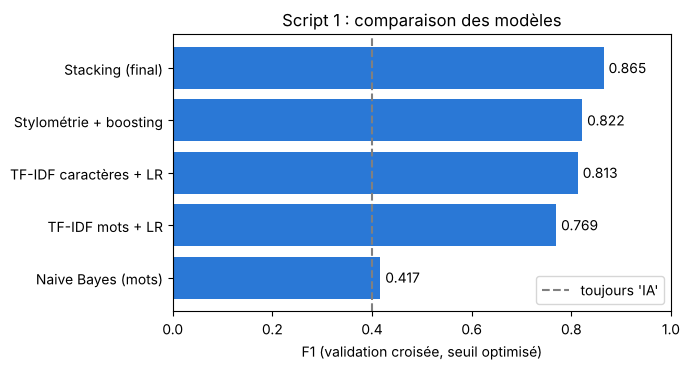

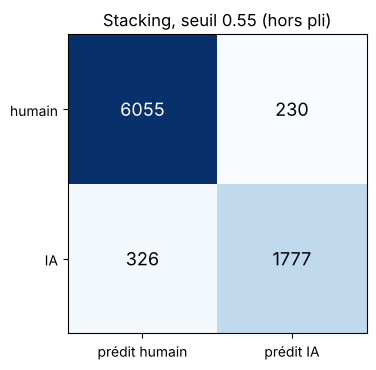

Matrice de confusion (lignes = vérité, colonnes = prédiction) :
[[6055  230]
 [ 326 1777]]

Pouvoir discriminant des variables stylométriques (AUC univariée) :
                      AUC plus élevé chez
titres_colles       0.796          humain
retours_ligne       0.709          humain
titres_deux_points  0.652              IA
doubles_espaces     0.628              IA
non_ascii           0.613              IA
deux_points         0.611              IA
titres_espace       0.593              IA
tirets_longs        0.587              IA
phrase_long_cv      0.586          humain
n_phrases           0.583          humain
apostrophes         0.580              IA
n_mots              0.563          humain


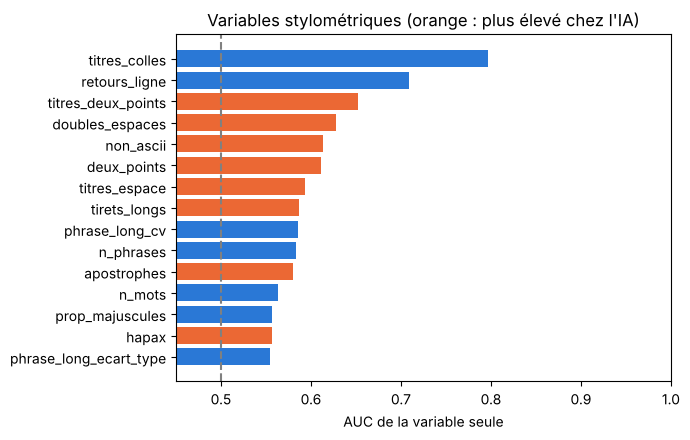

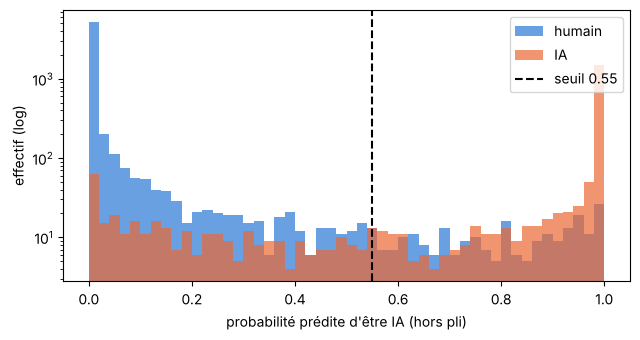

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

#comparaison des modèles (F1 au seuil optimisé)
meilleurs = resultats.loc[resultats.groupby("modèle")["F1"].idxmax()].sort_values("F1")
plt.figure(figsize=(7, 3.8))
plt.barh(meilleurs["modèle"], meilleurs["F1"], color="#2a78d6")
#référence "toujours IA", calculée sur les mêmes données que la validation croisée
plt.axvline(2 * y.mean() / (1 + y.mean()), color="grey", ls="--", label="toujours 'IA'")
for i, v in enumerate(meilleurs["F1"]):
    plt.text(v + 0.01, i, f"{v:.3f}", va="center")
plt.xlim(0, 1); plt.xlabel("F1 (validation croisée, seuil optimisé)")
plt.title("Script 1 : comparaison des modèles"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig1_comparaison_modeles.png"), dpi=200)
plt.show()

#matrice de confusion du modèle final
cm = confusion_matrix(y, pred_cv)                    #lignes = vérité, colonnes = prédiction
plt.figure(figsize=(4.5, 3.8))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=13)
plt.xticks([0, 1], ["prédit humain", "prédit IA"]); plt.yticks([0, 1], ["humain", "IA"])
plt.title(f"Stacking, seuil {SEUIL} (hors pli)")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig2_matrice_confusion.png"), dpi=200)
plt.show()
print(f"Matrice de confusion (lignes = vérité, colonnes = prédiction) :\n{cm}")

#AUC de chaque variable stylométrique prise seule
auc_var = pd.DataFrame({
    "AUC": [max(roc_auc_score(y, S[c]), 1 - roc_auc_score(y, S[c])) for c in S.columns],
    "plus élevé chez": ["IA" if roc_auc_score(y, S[c]) > 0.5 else "humain" for c in S.columns],
}, index=S.columns).sort_values("AUC", ascending=False)
print("\nPouvoir discriminant des variables stylométriques (AUC univariée) :")
print(auc_var.head(12).round(3).to_string())
auc_var.round(3).to_csv(os.path.join(dossier_figures, "auc_variables_stylometriques.csv"))
top = auc_var.head(15).iloc[::-1]
plt.figure(figsize=(7, 4.5))
plt.barh(top.index, top["AUC"],
         color=["#eb6834" if s == "IA" else "#2a78d6" for s in top["plus élevé chez"]])
plt.axvline(0.5, color="grey", ls="--")
plt.xlim(0.45, 1); plt.xlabel("AUC de la variable seule")
plt.title("Variables stylométriques (orange : plus élevé chez l'IA)")
plt.tight_layout(); plt.savefig(os.path.join(dossier_figures, "fig3_variables_stylometriques.png"), dpi=200)
plt.show()

#distribution des probabilités prédites
plt.figure(figsize=(6.5, 3.5))
plt.hist(p_final[y == 0], bins=50, alpha=0.7, label="humain", color="#2a78d6")
plt.hist(p_final[y == 1], bins=50, alpha=0.7, label="IA", color="#eb6834")
plt.axvline(SEUIL, color="black", ls="--", label=f"seuil {SEUIL}")
plt.yscale("log"); plt.xlabel("probabilité prédite d'être IA (hors pli)"); plt.ylabel("effectif (log)")
plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(dossier_figures, "fig4_distribution_probas.png"), dpi=200)
plt.show()

* Sur la matrice de confusion, le modèle détecte 1 777 abstracts IA et en rate 326. Il classe 230 humains IA à tort et 6 055 humains correctement. Il se trompe donc un peu plus en ratant des IA (faux négatifs) qu'en accusant des humains (faux positifs).
* Les variables les plus discriminantes sont les titres de section collés au texte (AUC = 0,80, plus fréquents chez les humains), les retours à la ligne (humains), les titres suivis de deux-points, les doubles espaces, les caractères non-ASCII et les tirets longs (IA). Ce sont surtout des indices de mise en forme. Parmi les variables de style proprement dit, la régularité des phrases (coefficient de variation plus élevé chez les humains) et le nombre de phrases jouent aussi un rôle.

## 6. bruit d'étiquetage
* Les abstracts « humains » sont ceux déposés par les auteurs, qui ont pu s'aider d'un outil d'IA pour les rédiger.
* Les humains que le modèle classe IA avec une très forte probabilité (au moins 0,9) sont donc des candidats à ce bruit d'étiquetage, ou simplement des erreurs du modèle.
* On enregistre les 30 plus suspects dans `humains_suspects_bruit_etiquetage.csv`.

In [12]:
suspects = donnees.assign(proba_IA=p_final)
suspects = suspects[suspects[COL_LABEL] == 0].sort_values("proba_IA", ascending=False)
n_suspects = int((suspects["proba_IA"] >= 0.9).sum())
print(f"Bruit d'étiquetage : {n_suspects} abstracts 'humains' ont une probabilité IA >= 0,9 "
      f"({n_suspects / (y == 0).sum():.1%} des humains)")
suspects.head(30)[["ID", "category", "proba_IA", "texte"]].to_csv(
    os.path.join(dossier_figures, "humains_suspects_bruit_etiquetage.csv"), index=False)

Bruit d'étiquetage : 78 abstracts 'humains' ont une probabilité IA >= 0,9 (1.2% des humains)


* **78 abstracts « humains » (1,2 %)** ont une probabilité IA d'au moins 0,9. En les lisant, certains ont peut-être été rédigés avec l'aide d'une IA (bruit d'étiquetage), d'autres sont de vraies erreurs du modèle.
* Ce bruit limite le F1 qu'on peut atteindre. Quand le modèle a raison sur un abstract étiqueté humain à tort, ça compte quand même comme une erreur.

## 7. robustesse du modèle sans les indices de mise en forme
* Le jeu de test peut contenir des textes générés par des LLM absents du train. Si le modèle s'appuie surtout sur la typographie, il risque de mal généraliser.
* Pour le vérifier, on normalise tous les textes avec les mêmes règles pour les deux classes (tirets longs, apostrophes, caractères non-ASCII, titres de section, espaces multiples), puis on refait toute la validation croisée.
* La baisse de F1 montre ce que le modèle doit aux artefacts de collecte, et ce qui reste correspond au vrai signal de style (vocabulaire, phrases...).

In [13]:
def normaliser_mise_en_forme(texte):
    #efface les indices de mise en forme pour ne garder que le contenu et le style d'écriture
    t = texte.replace("—", "-").replace("–", "-")       #tirets longs remplacés par '-'
    t = re.sub(r"['‘’\"“”]", "", t)           #apostrophes et guillemets
    t = re.sub(r"\{[a-z]+\}", "", t)                               #{rho}, {beta}...
    t = t.encode("ascii", "ignore").decode()                       #caractères non-ASCII
    t = re.sub(r"\b" + ENTETES + r"\s*[:.]?", " ", t)              #titres de section
    t = re.sub(r"\b(?:BACKGROUND|INTRODUCTION|OBJECTIVES?|METHODS|RESULTS|CONCLUSIONS?)\b\s*[:.]?", " ", t)
    return re.sub(r"\s+", " ", t).strip()                          #espaces multiples \n

if ANALYSE_ROBUSTESSE:
    print("Robustesse : même chaîne sur des textes normalisés...")
    X_norm = np.array([normaliser_mise_en_forme(t) for t in X])
    probas_norm = pipeline_complet(X_norm, y, tableau_stylometrique(X_norm))
    robu = pd.DataFrame({
        "texte brut": {k: meilleur_seuil(y, v)[1] for k, v in probas.items()},
        "texte normalisé": {k: meilleur_seuil(y, v)[1] for k, v in probas_norm.items()},
    })
    print("F1 (seuil optimisé) avec et sans les indices de mise en forme :")
    print(robu.round(3).to_string())
    robu.round(4).to_csv(os.path.join(dossier_figures, "robustesse_texte_normalise.csv"))

Robustesse : même chaîne sur des textes normalisés...


F1 (seuil optimisé) avec et sans les indices de mise en forme :
                        texte brut  texte normalisé
Naive Bayes (mots)           0.417            0.296
TF-IDF mots + LR             0.769            0.648
TF-IDF caractères + LR       0.813            0.654
Stylométrie + boosting       0.822            0.452
Stacking (final)             0.865            0.661


* Sans les indices de mise en forme, le F1 du stacking **tombe de 0,865 à 0,661**, et celui de la stylométrie seule de 0,822 à 0,452. Une bonne partie de la performance vient donc de la façon dont les textes ont été collectés (titres collés et apostrophes supprimées lors de l'extraction depuis medRxiv) et pas du style d'écriture.
* Ce qui reste (un F1 d'environ 0,65 pour les modèles TF-IDF) correspond au vrai signal de style, le vocabulaire et les tournures.
* Si le jeu de test a été construit de la même façon, ce que laissent penser les proportions d'indices vues à l'étape 1, le modèle devrait bien marcher. Sur des textes collectés ou générés autrement, il serait nettement moins bon.

## 8. modèle final et prédiction du fichier de test
* Les 2 modèles TF-IDF sont réentraînés sur tout le jeu d'entraînement, et le modèle de niveau 2 est entraîné sur les probabilités hors pli (comme en validation).
* Pour l'interprétation, on regarde les mots et bigrammes les plus associés à chaque classe grâce aux coefficients de la régression logistique (un coefficient positif pousse vers IA).
* On applique au fichier test le même nettoyage, le modèle final donne une probabilité et le seuil la transforme en **0 ou 1**. Les abstracts vides sont classés 1 (100 % IA dans le train).
* On enregistre un fichier .csv à 2 colonnes `ID` et `pred`, plus un fichier avec les probabilités sur le test (utile si on veut combiner les deux scripts). Si le fichier test contient la colonne HumanAI (par exemple un jeu de validation mis de côté), le F1 s'affiche directement.

In [14]:
print("Entraînement final sur tout le jeu d'entraînement...")
#niveau 1, les deux modèles TF-IDF réentraînés sur toutes les données
m_mots = modele_mots().fit(X, y)
m_car = modele_caracteres().fit(X, y)
#niveau 2 entraîné sur les probabilités hors pli (comme en validation)
m_final = modele_boosting().fit(
    construire_niveau2(S, probas["TF-IDF mots + LR"], probas["TF-IDF caractères + LR"]), y)

#interprétation, n-grammes de mots les plus associés à chaque classe
vocab = m_mots[0].get_feature_names_out()
coefs = m_mots[1].coef_[0]                    #un coefficient positif pousse vers "IA"
ordre = np.argsort(coefs)
print("\nMots/bigrammes les plus 'IA'     :", ", ".join(vocab[ordre[-20:][::-1]]))
print("Mots/bigrammes les plus 'humain' :", ", ".join(vocab[ordre[:20]]))

#prédiction du test
X_test = test["texte"].values
Z_test = construire_niveau2(tableau_stylometrique(X_test),
                            m_mots.predict_proba(X_test)[:, 1],
                            m_car.predict_proba(X_test)[:, 1])
proba_test = m_final.predict_proba(Z_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)
#règle pour les abstracts vides (100 % IA dans le jeu d'entraînement)
vide_test = (test["texte"] == "").values
pred_test[vide_test] = 1
proba_test[vide_test] = 1.0

#fichier de prédiction avec 2 colonnes, ID et pred
sortie = pd.DataFrame({"ID": test["ID"], "pred": pred_test})
sortie.to_csv(fichier_sortie, index=False)
#on garde aussi les probabilités sur le test (utiles pour combiner avec le script 2)
pd.DataFrame({"ID": test["ID"], "proba_IA": proba_test}).to_csv(
    fichier_sortie.replace(".csv", "_probas.csv"), index=False)

print(f"\n{len(sortie)} abstracts prédits dont {pred_test.sum()} IA ({pred_test.mean():.1%}), "
      f"dont {vide_test.sum()} abstracts vides -> {fichier_sortie}")
print(f"(part d'IA dans le train : {part_ia:.1%})")

#si le fichier test contient les étiquettes, on affiche directement les performances
if COL_LABEL in test.columns:
    print(f"F1 = {f1_score(test[COL_LABEL], pred_test):.3f} | "
          f"précision = {precision_score(test[COL_LABEL], pred_test):.3f}")

Entraînement final sur tout le jeu d'entraînement...



Mots/bigrammes les plus 'IA'     : background, methods, conclusions, results, conclusion, methods we, utilized, regarding, this study, employed, while, objective, although, furthermore, utilizing, exhibited, results the, employed to, objective to, the
Mots/bigrammes les plus 'humain' : methodswe, but, resultsthe, used, methodsa, here, showed, c_li, methodsthis, objectiveto, show, here we, had, about, methodswe conducted, analysed, together, show that, important, compared with



2898 abstracts prédits dont 838 IA (28.9%), dont 223 abstracts vides -> predictions_script1.csv
(part d'IA dans le train : 28.7%)


* Parmi les mots les plus « IA », on trouve background, methods, results et conclusion. Ce sont des titres séparés du texte, alors qu'ils sont collés chez les humains, donc c'est encore un artefact. Viennent ensuite de vrais tics de LLM comme utilized, employed, regarding, furthermore, exhibited, while ou although.
* Côté humain, on trouve methodswe et resultsthe (les titres collés), mais aussi but, used, here we, showed ou analysed (orthographe britannique).
* Sur le fichier test, **838 abstracts sont prédits IA** (28,9 %), dont 223 abstracts vides. C'est très proche de la part d'IA du jeu d'entraînement (28,7 %).

## 9. conclusion
* Le **modèle final** est un stacking (gradient boosting) qui combine un TF-IDF sur les mots, un TF-IDF sur les caractères et 32 variables stylométriques, avec un seuil de 0,55.
* Il obtient un **F1 de 0,865** en validation croisée stratifiée à 5 plis (précision 0,885, rappel 0,845), soit **environ 0,90** en comptant les abstracts vides.
* Le F1 n’est pas optimiste à cause du stacking ou du choix du seuil, car une validation croisée imbriquée (niveau 1, niveau 2 et seuil choisis sans les abstracts évalués) donne aussi 0,865.
* Pour le déséquilibre des classes, on a utilisé `class_weight="balanced"` et un seuil choisi pour maximiser le F1.
* On a gardé un nettoyage léger, car le prétraitement classique (mots vides, racinisation) fait baisser le F1 en effaçant des indices de style.
* Pour la généralisation, la performance repose en partie sur des artefacts de mise en forme (F1 de 0,661 sans eux). C'est un risque si le test contient des textes collectés ou générés autrement.
* Côté bruit d'étiquetage, 1,2 % des abstracts « humains » sont classés IA avec une très forte probabilité.
* Il y a quelques limites :
  * quelques réglages ont été choisis par essais
  * ces méthodes ne tiennent pas compte du contexte des mots, ce que fait le script 2